# 02: Exploratory data analysis

This notebook explores what drives daily unit sales in 54 Favorita stores in Ecuador (January 2013 to August 2017). Each chapter tests one hypothesis and ends with a decision for the forecasting model.

## Setup

In [ ]:
import os
from urllib.parse import quote_plus

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine

pd.set_option('display.expand_frame_repr', False)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 4)

In [ ]:
load_dotenv('../.env')

user = os.getenv('DB_USER')
password = quote_plus(os.getenv('DB_PASSWORD'))  # URL-encode: special characters break the URL
host = os.getenv('DB_HOST')
port = os.getenv('DB_PORT')
database = os.getenv('DB_NAME')

url = f'postgresql+psycopg2://{user}:{password}@{host}:{port}/{database}'
engine = create_engine(url)


def run_query(sql):
    return pd.read_sql(sql, engine)

Does the connection work?

In [ ]:
check = run_query('select count(*) as row_count from analytics_marts.fct_sales_daily_store_family')
print(check)

   row_count
0    2061903


## Data readiness: what the warehouse already guarantees

This notebook reads only the dbt marts in PostgreSQL. The pipeline before it already checks the data, so this notebook does not repeat those checks.

- **Raw load:** all six Kaggle files are loaded unchanged, and the row counts match the source files.
- **Tests:** 49 dbt data tests pass. They check unique and non-null keys, the joins to the dimensions, and an exact reconciliation of the daily aggregate with `fct_sales`.
- **Known data issues:** 25 issues are recorded, each with how it is handled. See [docs/data_issues.md](../docs/data_issues.md).
- **Tables and columns:** see [docs/data_dictionary.md](../docs/data_dictionary.md).
- **Kept as recorded on purpose:** returns stay negative (DI-14), `onpromotion` is empty before 2014-04-01 (DI-13), and days with zero sales have no row (DI-11). This notebook takes these into account.

## 1. Target profile

What daily sales look like for one item in one store, the level the forecast works at.

**Context:** The profiling notebook describes `unit_sales` row by row: median 4, 75% of rows at 9 or less, a range of −15,372 to 89,440, and 7,795 returns. Only 34% of the 367,017,696 possible store × item × day rows exist, because days with zero sales have no row (DI-11). This chapter moves from rows to series. A series is one item in one store, day by day. It uses the proposed training window, 2014-04-01 to 2017-08-15 (DI-13).

**Hypotheses:**
- 1.1: Most series have zero sales on most days, so the table after zero-fill is much larger than `fct_sales`.
- 1.2: A small share of the items, about 20%, makes 80% of the units sold.
- 1.3: Most series sell rarely (intermittent or lumpy), not often.

1.1 How sparse is each series, and how big is the table after zero-fill? First, one summary row per series (one item in one store).

In [ ]:
series_sql = """
select
    store_nbr,
    item_nbr,
    min(date) as first_sale_date,
    max(date) as last_sale_date,
    count(*) as rows_in_data,
    count(*) filter (where unit_sales > 0) as days_with_sales,
    avg(unit_sales) filter (where unit_sales > 0) as mean_when_sold,
    stddev_pop(unit_sales) filter (where unit_sales > 0) as std_when_sold
from analytics_marts.fct_sales
where date >= '2014-04-01'
group by store_nbr, item_nbr
"""

series = run_query(series_sql)
print(series.shape)
print(series.head())

(174064, 8)
   store_nbr  item_nbr first_sale_date last_sale_date  rows_in_data  days_with_sales  mean_when_sold  std_when_sold
0          1     96995      2014-07-19     2017-08-10            34               34        1.352941       0.588235
1          1     99197      2014-08-20     2017-08-09           185              185        2.772973       2.299782
2          1    103520      2014-04-01     2017-08-13           798              798        2.878446       4.113553
3          1    103665      2014-04-01     2017-08-15           986              985        3.566497       2.427820
4          1    105574      2014-04-01     2017-08-15          1133             1133        5.394528       4.360685


How many rows does the table have after zero-fill, and what share of active days have zero sales?

In [ ]:
last_date_in_data = pd.Timestamp('2017-08-15')

series['first_sale_date'] = pd.to_datetime(series['first_sale_date'])
series['last_sale_date'] = pd.to_datetime(series['last_sale_date'])

# +1 because both ends count: 1 Aug to 7 Aug is 6 days apart, but 7 days
series['active_days'] = (series['last_sale_date'] - series['first_sale_date']).dt.days + 1
series['active_days_to_data_end'] = (last_date_in_data - series['first_sale_date']).dt.days + 1

print('series: ', len(series))
print('rows in data: ', series['rows_in_data'].sum())
print('rows after zero-fill (active days): ', series['active_days'].sum())
print('rows after zero-fill, if active to data end: ', series['active_days_to_data_end'].sum())
print()

overall_share_of_zero_days = 1 - series['days_with_sales'].sum() / series['active_days'].sum()
print('overall share of zero days: ', overall_share_of_zero_days)

series:  174064
rows in data:  103839389
rows after zero-fill (active days):  155317677
rows after zero-fill, if active to data end:  160486563

overall share of zero days:  0.33148046632193706


How different are the series from each other?

   store_nbr  item_nbr  active_days  days_with_sales  share_of_zero_days
0          1     96995         1119               34            0.969616
1          1     99197         1086              185            0.829650
2          1    103520         1231              798            0.351747
3          1    103665         1233              985            0.201135
4          1    105574         1233             1133            0.081103

count    174064.000000
mean          0.351522
std           0.271792
min           0.000000
25%           0.125000
50%           0.282238
75%           0.549874
max           1.000000
Name: share_of_zero_days, dtype: float64


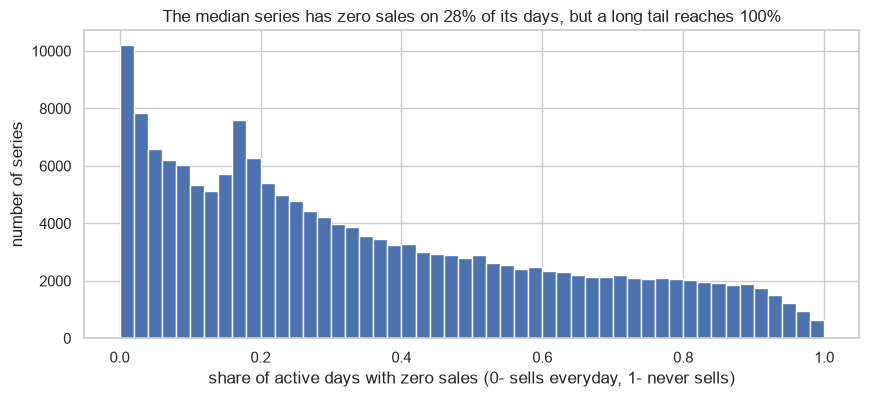

In [ ]:
# the share of zero days for each series on its own
series['share_of_zero_days'] = 1 - series['days_with_sales'] / series['active_days']

print(series[['store_nbr', 'item_nbr', 'active_days', 'days_with_sales', 'share_of_zero_days']].head())
print()
print(series['share_of_zero_days'].describe())

plt.hist(series['share_of_zero_days'], bins=50)
plt.title('The median series has zero sales on 28% of its days, but a long tail reaches 100%')
plt.xlabel('share of active days with zero sales (0- sells everyday, 1- never sells)')
plt.ylabel('number of series')
plt.show()

### 1.1 Findings

- **Series:** 174,064 series (one item in one store) sell at least once between 2014-04-01 and 2017-08-15.
- **Size after zero-fill:** 155,317,677 rows. The data has 103,839,389 rows, so zero-fill adds 50%.
- **Zero days:** 33.1% of active days have no sales. The hypothesis is rejected: most days have a sale.
- **Why profiling looked sparser:** most missing rows are days before an item went on sale, not days with zero sales.
- **Series differ a lot:** the median series has no sales on 28% of its days. Some series sell every day, and some almost never.
- **Closed days:** the [profiling notebook](01_profiling.ipynb) found no rows on Christmas Day, and only 1,718 rows on 1 January 2016 (about 100,000 on a normal day). The stores were closed, so a zero on those days does not mean "no demand".

**Decision:** fill zeros only inside each series' active period, and only on days when the store sold something. This leaves out Christmas, New Year's Day and any other day a store was closed.

**Limitation:** a store that sold nothing is treated as closed. It could have been open with no sales, but for a whole store that is unlikely. The window start (2014-04-01) is still a proposal.

1.2 What share of the items makes 80% of the units sold?

In [ ]:
items_sql = """
select
    item_nbr,
    sum(cast(unit_sales as numeric)) as units_sold
from analytics_marts.fct_sales
where date >= '2014-04-01'
group by item_nbr
"""

items = run_query(items_sql)
items['units_sold'] = items['units_sold'].astype(float)
print(items.shape)

(4036, 2)


How do the units add up from the biggest seller to the smallest?

items:  4036
items needed for 80% of units:  1624
share of items:  0.40237859266600595


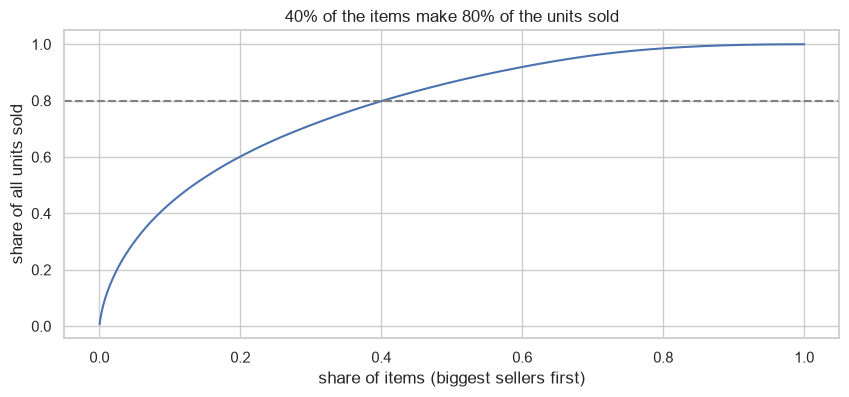

In [ ]:
# step 1: sort from the biggest seller to the smallest
items = items.sort_values('units_sold', ascending=False).reset_index(drop=True)

# step 2: running total, as a share of all units
items['running_total'] = items['units_sold'].cumsum()
items['share_of_units'] = items['running_total'] / items['units_sold'].sum()

# share of items so far: 1st item = 1/n, 2nd item = 2/n, ...
items['item_rank'] = range(1, len(items) + 1)
items['share_of_items'] = items['item_rank'] / len(items)

# step 3: how many items do we need to pass 80%?
items_needed = (items['share_of_units'] < 0.8).sum() + 1
print('items: ', len(items))
print('items needed for 80% of units: ', items_needed)
print('share of items: ', items_needed / len(items))

plt.plot(items['share_of_items'], items['share_of_units'])
plt.axhline(0.8, color='grey', linestyle='--')
plt.title('40% of the items make 80% of the units sold')
plt.xlabel('share of items (biggest sellers first)')
plt.ylabel('share of all units sold')
plt.show()

### 1.2 Findings

- **Items:** 4,036 items sell between 2014-04-01 and 2017-08-15.
- **Concentration:** 1,624 items (40%) make 80% of the units sold. The hypothesis (about 20%) is rejected: sales are spread over more items than the 80/20 rule suggests.
- **The rest:** the other 2,412 items (60%) make only 20% of the units.

**Decision:** score the forecast with WAPE overall, and also per family and per demand type, so the smaller items are not hidden.

**Limitation:** units are not money. A kilo of meat and a bottle of water each count as one unit, and the data has no prices. So "biggest seller" means the most units, not the most revenue.

1.3 How many series are smooth, erratic, intermittent or lumpy?

In [ ]:
# a series with no day with a sale (only returns) has no ADI or CV², so it is left out
series_with_sales = series[series['days_with_sales'] > 0].copy()
print('series left out (no day with a sale): ', len(series) - len(series_with_sales))
print()

series_with_sales['adi'] = series_with_sales['active_days'] / series_with_sales['days_with_sales']
series_with_sales['cv_squared'] = (series_with_sales['std_when_sold'] / series_with_sales['mean_when_sold']) ** 2


# cut-offs from Syntetos, Boylan and Croston (2005)
def demand_type(row):
    sells_often = row['adi'] < 1.32
    amounts_stable = row['cv_squared'] < 0.49
    if sells_often and amounts_stable:
        return 'smooth'
    if sells_often and not amounts_stable:
        return 'erratic'
    if not sells_often and amounts_stable:
        return 'intermittent'
    return 'lumpy'


series_with_sales['demand_type'] = series_with_sales.apply(demand_type, axis=1)

series_per_type = series_with_sales['demand_type'].value_counts()
print(series_per_type)
print()
print(series_per_type / len(series_with_sales))

series left out (no day with a sale):  1

demand_type
lumpy           54061
intermittent    42166
smooth          41161
erratic         36675
Name: count, dtype: int64

demand_type
lumpy           0.310583
intermittent    0.242246
smooth          0.236472
erratic         0.210700
Name: count, dtype: float64


What share of the units does each demand type sell?

              share_of_series  share_of_units
demand_type                                  
smooth               0.236472        0.521115
erratic              0.210700        0.310997
intermittent         0.242246        0.053563
lumpy                0.310583        0.114325


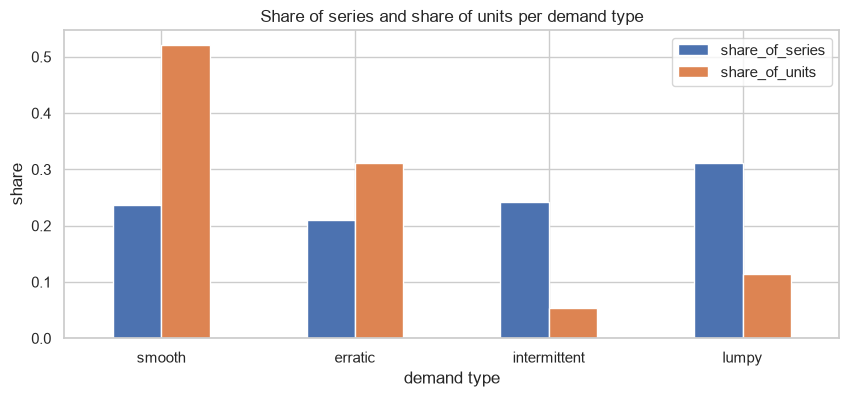

In [ ]:
# units sold on sale days = average amount when sold × number of days with a sale
series_with_sales['units_sold'] = series_with_sales['mean_when_sold'] * series_with_sales['days_with_sales']
units_per_type = series_with_sales.groupby('demand_type')['units_sold'].sum()

type_order = ['smooth', 'erratic', 'intermittent', 'lumpy']
summary = pd.DataFrame({
    'share_of_series': series_per_type / len(series_with_sales),
    'share_of_units': units_per_type / units_per_type.sum(),
})
summary = summary.loc[type_order]
print(summary)

summary.plot(kind='bar')
plt.title('Share of series and share of units per demand type')
plt.xlabel('demand type')
plt.ylabel('share')
plt.xticks(rotation=0)
plt.show()

### 1.3 Findings

- **Demand types:** 31% of the series are lumpy, 24% intermittent, 24% smooth and 21% erratic. One series has no day with a sale and is left out.
- **Most series sell rarely:** intermittent and lumpy series together are 55% of the series. The hypothesis is supported, but only just.
- **Units are the other way round:** series that sell often (smooth and erratic) are 45% of the series but sell 83% of the units. Series that sell rarely sell only 17%.

**Decision:** report every forecast's WAPE per demand type as well as overall, so the series that sell rarely are not hidden.

**Limitation:** the types use the whole window, including the days that will become the test period. That is fine for reporting results. If the type is ever used as a model feature, it must be computed on the training days only. Series with only a few sale days get a less reliable CV².